# Digital Image Processing: Three Simple Case Studies
**Course project — introductory level**

This notebook demonstrates coin counting, document enhancement, and impulse-noise removal. It uses basic thresholding, connected components, and median filtering, not deep learning.

**Google Colab:** upload this `.ipynb` to https://colab.research.google.com/ and select **Runtime → Run all**. No Drive mount, API key, or repository clone is needed. All images come from the official scikit-image sample collection. Figures and measurements are saved in the current runtime directory.

The examples are demonstrations, not validated industrial systems. Read the assumptions and failure cases before interpreting the results.

In [1]:
# Colab normally includes these packages. Install only if an import is missing.
import importlib.util
import subprocess
import sys

packages = {"numpy": "numpy>=1.24,<3", "matplotlib": "matplotlib>=3.7,<4",
            "skimage": "scikit-image>=0.22,<0.26"}
missing = [requirement for module, requirement in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])

In [2]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
import skimage
from skimage import data, filters, morphology, measure, segmentation, util, io
from skimage.metrics import mean_squared_error, peak_signal_noise_ratio

for folder in ["images", "figures", "results"]:
    Path(folder).mkdir(exist_ok=True)

def show_images(images, titles, filename):
    fig, axes = plt.subplots(1, len(images), figsize=(12, 4))
    for ax, image, title in zip(axes, images, titles):
        ax.imshow(image, cmap="gray", vmin=0, vmax=1)
        ax.set_title(title)
        ax.axis("off")
    fig.tight_layout()
    fig.savefig("figures/" + filename, dpi=200, bbox_inches="tight")
    plt.show()

results = {"versions": {"numpy": np.__version__, "skimage": skimage.__version__}}
print(results["versions"])

{'numpy': '2.0.2', 'skimage': '0.24.0'}


## 1. Counting separated coins
**Problem:** count bright, separated objects against a darker background.

**Features:** foreground intensity, connected-component area (pixels), centroid, and circularity $4\pi A/P^2$. Area removes tiny background regions; circularity describes a round outline but is not a coin-denomination classifier.

**Method:** Gaussian smoothing → Otsu threshold → remove small objects and fill small holes → remove border objects → label components. We manually count **24 coins** in this particular image as a simple reference. This is not a separate test dataset.

Detected objects: 21 | Manual reference: 24
First five feature rows: [{'label': 1, 'area_px': 2665, 'circularity': 0.9147537223359731, 'centroid_row_col': [np.float64(43.23076923076923), np.float64(334.674296435272)]}, {'label': 2, 'area_px': 1683, 'circularity': 0.9180258105150967, 'centroid_row_col': [np.float64(51.04872251931076), np.float64(215.17052881758764)]}, {'label': 3, 'area_px': 1267, 'circularity': 0.9270156892473613, 'centroid_row_col': [np.float64(52.25966850828729), np.float64(276.0505130228887)]}, {'label': 4, 'area_px': 1913, 'circularity': 0.8961770979312026, 'centroid_row_col': [np.float64(119.083638264506), np.float64(270.7156299006796)]}, {'label': 5, 'area_px': 1408, 'circularity': 0.9087002574905484, 'centroid_row_col': [np.float64(124.21661931818181), np.float64(44.75426136363637)]}]


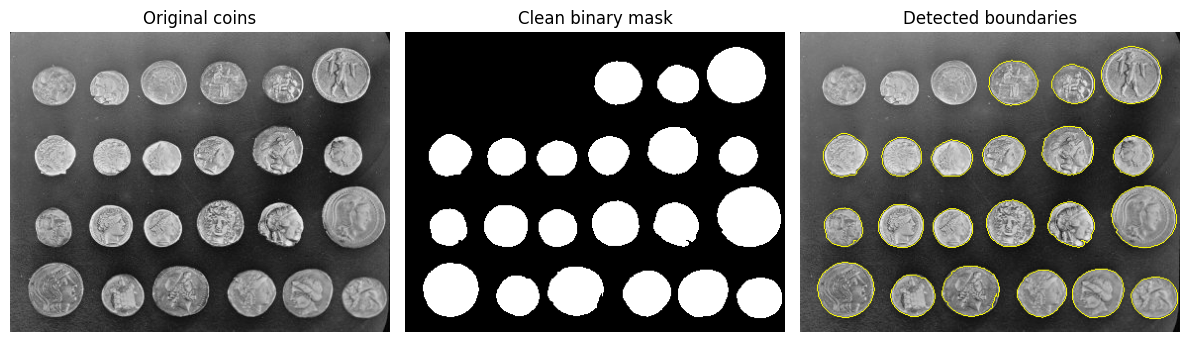

In [3]:
coins = util.img_as_float(data.coins())
io.imsave("images/coins.png", util.img_as_ubyte(coins))
smooth = filters.gaussian(coins, sigma=1)
threshold = filters.threshold_otsu(smooth)
mask = smooth > threshold
mask = morphology.remove_small_objects(mask, min_size=120)
mask = morphology.remove_small_holes(mask, area_threshold=120)
mask = segmentation.clear_border(mask)
labels = measure.label(mask)
regions = measure.regionprops(labels)

coin_features = []
for region in regions:
    circularity = 4 * np.pi * region.area / max(region.perimeter ** 2, 1)
    coin_features.append({"label": int(region.label), "area_px": int(region.area),
                          "circularity": float(circularity),
                          "centroid_row_col": list(region.centroid)})

results["coins"] = {"threshold": float(threshold), "count": len(regions),
                     "manual_reference": 24, "features": coin_features}
print("Detected objects:", len(regions), "| Manual reference: 24")
print("First five feature rows:", coin_features[:5])
show_images([coins, mask, segmentation.mark_boundaries(coins, labels)],
            ["Original coins", "Clean binary mask", "Detected boundaries"], "coins_results.png")

### Interpretation
Check the boundary image: one label should correspond to one coin. Otsu's global threshold is intentionally simple; uneven illumination can split a coin or join it to the background. Touching coins may merge into a single component. Border clearing can discard valid objects touching the edge. The reported number is the actual algorithm output, not a hard-coded expected result.

## 2. Enhancing a scanned document
**Problem:** separate dark printed text from a page with uneven background brightness.

**Features:** local gray-level contrast, foreground-pixel fraction, and connected-component area. These describe binarization, not recognized words.

**Method:** compare a global Otsu threshold with a local threshold calculated in a 35 × 35 neighborhood. A pixel is text when its intensity is lower than the threshold. The local offset is 0.03 on the [0, 1] scale.

{
  "global_foreground_fraction": 0.3568117364746946,
  "local_foreground_fraction": 0.14768760907504364,
  "local_component_count": 291,
  "median_component_area_px": 35.0
}


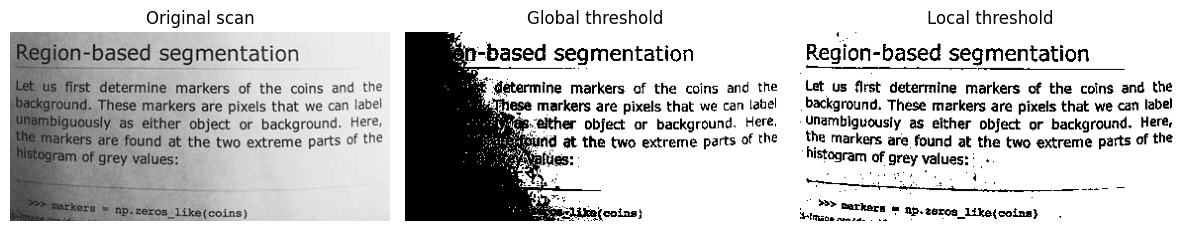

In [4]:
page = util.img_as_float(data.page())
io.imsave("images/page.png", util.img_as_ubyte(page))
global_text = page < filters.threshold_otsu(page)
local_threshold = filters.threshold_local(page, block_size=35, offset=0.03)
local_text = page < local_threshold

text_labels = measure.label(local_text)
text_regions = measure.regionprops(text_labels)
results["document"] = {
    "global_foreground_fraction": float(global_text.mean()),
    "local_foreground_fraction": float(local_text.mean()),
    "local_component_count": len(text_regions),
    "median_component_area_px": float(np.median([r.area for r in text_regions]))}
print(json.dumps(results["document"], indent=2))
show_images([page, ~global_text, ~local_text],
            ["Original scan", "Global threshold", "Local threshold"], "document_results.png")

### Interpretation
The local threshold responds to background changes more flexibly than a single global threshold. Inspect thin strokes and punctuation as well as background cleanliness. Foreground fraction is a diagnostic, not an accuracy score: a lower fraction might mean cleaner paper or missing letters. Components can be letters, dots, or joined strokes, so their count is **not** a character count. OCR accuracy cannot be claimed because no transcription is evaluated.

## 3. Removing salt-and-pepper noise from a photograph
**Problem:** restore a photograph affected by random black and white impulse pixels.

**Features:** extreme-intensity pixels and local neighborhood consistency suggest impulse noise. Pixel differences against a clean reference provide MSE and PSNR evaluation features, not inference-time inputs.

**Method:** add reproducible synthetic noise to the clean image, then compare a Gaussian filter (sigma = 1) with a 3 × 3 median filter. The clean image is available here only because the corruption is simulated.

{
  "noisy": {
    "mse": 0.016706509705645817,
    "psnr_db": 17.771142726624415
  },
  "gaussian": {
    "mse": 0.002703745810859009,
    "psnr_db": 25.680341404413312
  },
  "median": {
    "mse": 0.0009730747432628074,
    "psnr_db": 30.118537996700937
  }
}


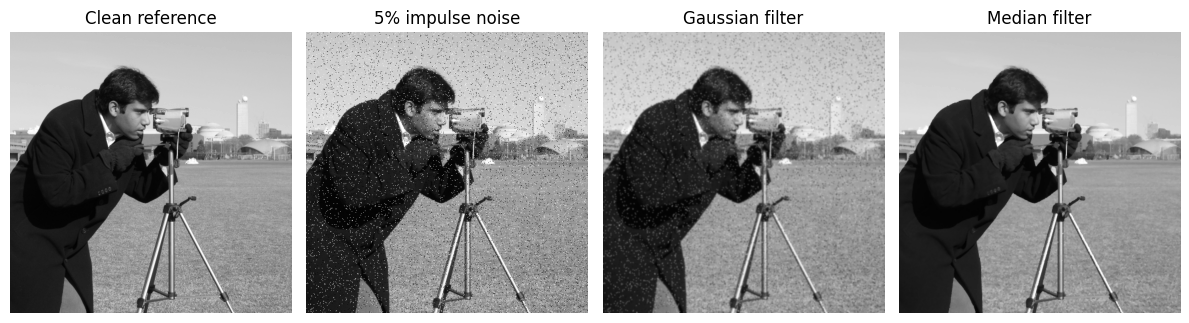

Saved figures and results/metrics.json


In [5]:
camera = util.img_as_float(data.camera())
io.imsave("images/camera.png", util.img_as_ubyte(camera))
rng = np.random.default_rng(42)
random_values = rng.random(camera.shape)
noisy = camera.copy()
noisy[random_values < 0.025] = 0
noisy[random_values > 0.975] = 1
gaussian = filters.gaussian(noisy, sigma=1)
median = filters.median(noisy, footprint=np.ones((3, 3), dtype=bool))

results["denoising"] = {}
for name, image in [("noisy", noisy), ("gaussian", gaussian), ("median", median)]:
    results["denoising"][name] = {
        "mse": float(mean_squared_error(camera, image)),
        "psnr_db": float(peak_signal_noise_ratio(camera, image, data_range=1))}
print(json.dumps(results["denoising"], indent=2))
show_images([camera, noisy, gaussian, median],
            ["Clean reference", "5% impulse noise", "Gaussian filter", "Median filter"], "denoising_results.png")

Path("results/metrics.json").write_text(json.dumps(results, indent=2))
print("Saved figures and results/metrics.json")

### Interpretation and limitations
Lower MSE and higher PSNR indicate closer agreement with this clean reference. Median filtering is well matched to sparse impulse noise because the median rejects isolated extremes. Gaussian filtering averages those extremes into neighboring pixels. Neither method preserves every fine detail, and the ranking should not be generalized to every noise model. One image and one noise seed are not a benchmark.

## Feature-selection summary
| Case | Suitable features | Why they help | Main limitation |
|---|---|---|---|
| Coin counting | Intensity, area, centroid, circularity | Separate and describe individual objects | Touching objects and shadows |
| Document enhancement | Local intensity, local contrast, component size, text fraction | Separate dark strokes from varying paper brightness | Thin strokes, textured paper, no OCR evaluation |
| Impulse denoising | Extreme pixels, neighborhood median; reference MSE/PSNR for evaluation | Identify outliers and quantify controlled restoration | Texture loss; clean reference rarely exists in real use |

## Sources and image credits
Images were located through a web search for the official scikit-image sample collection, then loaded from the documented original collection rather than from Google thumbnails.
- Image documentation: https://scikit-image.org/docs/0.24.x/api/skimage.data.html
- Coins: Greek coins from Pompeii; Brooklyn Museum collection; documentation states **no known copyright restrictions**.
- Camera: photograph by **Lav Varshney**, **CC0**; use the modern scikit-image version, not the older copyrighted cameraman image.
- Page: scanned-page sample distributed with scikit-image; the API does not identify a separate photographer or image-specific license. The upstream project has a general BSD-3-Clause notice; do not infer a separate public-domain declaration for this image: https://github.com/scikit-image/scikit-image/blob/v0.24.0/LICENSE.txt
- Otsu: https://doi.org/10.1109/TSMC.1979.4310076
- scikit-image paper: https://doi.org/10.7717/peerj.453

**Conclusion:** simple methods work when their assumptions fit the image. Feature selection should follow the problem, not the other way around.